In [6]:
from pathlib import Path

# enable ipympl widgets for zoom
# %matplotlib widget
#%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
#from matplotlib.ticker import FixedLocator
from matplotlib.ticker import NullLocator, AutoMinorLocator, MultipleLocator
from matplotlib.lines import Line2D
import pandas as pd
from pint import UnitRegistry, set_application_registry
import pint_pandas  # needed for initialization
import numpy as np
import statsmodels.formula.api as smf
import statsmodels.api as sm

ureg = UnitRegistry()
set_application_registry(ureg)

In [7]:
#sns.set_theme()
#sns.set_theme(style="white")
#sns.set_theme(style="whitegrid")
#sns.set_theme(style="ticks")
sns.set_theme(
    style="ticks",
    context="paper",
    rc={
        "axes.linewidth": 0.8,
        "xtick.direction": "out",
        "ytick.direction": "out"
    }
)

In [8]:
def import_dataset(filename: Path):
    df = pd.read_csv(filename, header=[0, 1])

    names = df.columns.get_level_values(0)
    units = df.columns.get_level_values(1)

    df.columns = names  # flatten
    if 'timestamp' in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], format="ISO8601")
    for col, unit in zip(names, units):  # apply units
        if unit != "No Unit":
            df[col] = df[col].astype(f"pint[{unit}]")

    return df

In [9]:
experiment_folder = Path("../data_processing")
resources_folder = experiment_folder / "resources"
df = import_dataset(resources_folder / "ee_measurements.csv")

In [10]:
def extract_comp_dataframe(df: pd.DataFrame, threading: str, mode: str) -> pd.DataFrame:
    comp = df.copy()
    comp = comp[comp["mode"] == mode]
    comp = comp[comp["threading"] == threading]
    return comp

In [11]:
def calculate_base(df: pd.DataFrame) -> pd.DataFrame:
    reference = 1 * ureg.byte / ureg.joule
    
    normalized_total = df["energy_efficiency_total"] / reference
    df["log_energy_efficiency_total"] = np.log(normalized_total).pint.magnitude

    normalized_net = df["energy_efficiency_net"] / reference
    df["log_energy_efficiency_net"] = np.log(normalized_net).pint.magnitude

    return df

In [12]:
def fit_two_way_model(data: pd.DataFrame, response):
    formula = f"""
    {response} ~ (
        C(host, Sum)
        + C(tool, Sum)
        + C(dataset, Sum)
        + C(strength, Sum)
    )**2
    """

    return smf.ols(
        formula=formula,
        data=data
    ).fit()

In [14]:
def fit_higher_order_models(data: pd.DataFrame, response):
    three_way_formula = f"""
        {response} ~ (
            C(host, Sum)
            + C(tool, Sum)
            + C(dataset, Sum)
            + C(strength, Sum)
        )**3
    """

    full_formula = f"""
        {response} ~
        C(host, Sum) *
        C(tool, Sum) *
        C(dataset, Sum) *
        C(strength, Sum)
    """

    three_way_model = smf.ols(
        formula=three_way_formula,
        data=data
    ).fit()

    full_model = smf.ols(
        formula=full_formula,
        data=data
    ).fit()

    return three_way_model, full_model

In [27]:
def plot_model_diagnostics(model, kind, title):
    rmse = np.sqrt(model.mse_resid)

    print(
        f"{kind.capitalize()}: {title}: "
        f"R²={model.rsquared:.6f}, "
        f"RMSE={rmse:.6f}"
    )

    diagnostics = pd.DataFrame({
        "fitted": model.fittedvalues,
        "residual": model.resid,
    })    

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.residplot(
        data=diagnostics,
        x="fitted",
        y="residual",
        lowess=True,
        scatter_kws={"alpha": 0.2, "s": 8},
        line_kws={"color": "red"},
        ax=axes[0]
    )
    axes[0].axhline(0, color="black", linestyle="--")
    axes[0].set_xlabel(f"Fitted log {kind}")
    axes[0].set_ylabel("Residual")
    axes[0].set_title("Residuals vs fitted")

    sm.qqplot(
        diagnostics["residual"],
        line="45",
        fit=True,
        ax=axes[1]
    )
    axes[1].set_title("Q–Q plot")

    sns.histplot(
        data=diagnostics,
        x="residual",
        bins=60,
        kde=True,
        ax=axes[2]
    )
    axes[2].axvline(0, color="black", linestyle="--", linewidth=1)
    axes[2].set_title("Distribution of residuals")
    axes[2].set_xlabel("Residue")    

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [54]:
comp = extract_comp_dataframe(df, "single", "compress")
comp = calculate_base(comp)

In [55]:
total_two_way_model = fit_two_way_model(comp,"log_energy_efficiency_total")
total_three_way_model, total_full_model = fit_higher_order_models(comp, "log_energy_efficiency_total")

net_two_way_model = fit_two_way_model(comp, "log_energy_efficiency_net")
net_three_way_model, net_full_model = fit_higher_order_models(comp, "log_energy_efficiency_net")

Total energy efficiency: full model: R²=0.998234, RMSE=0.068182


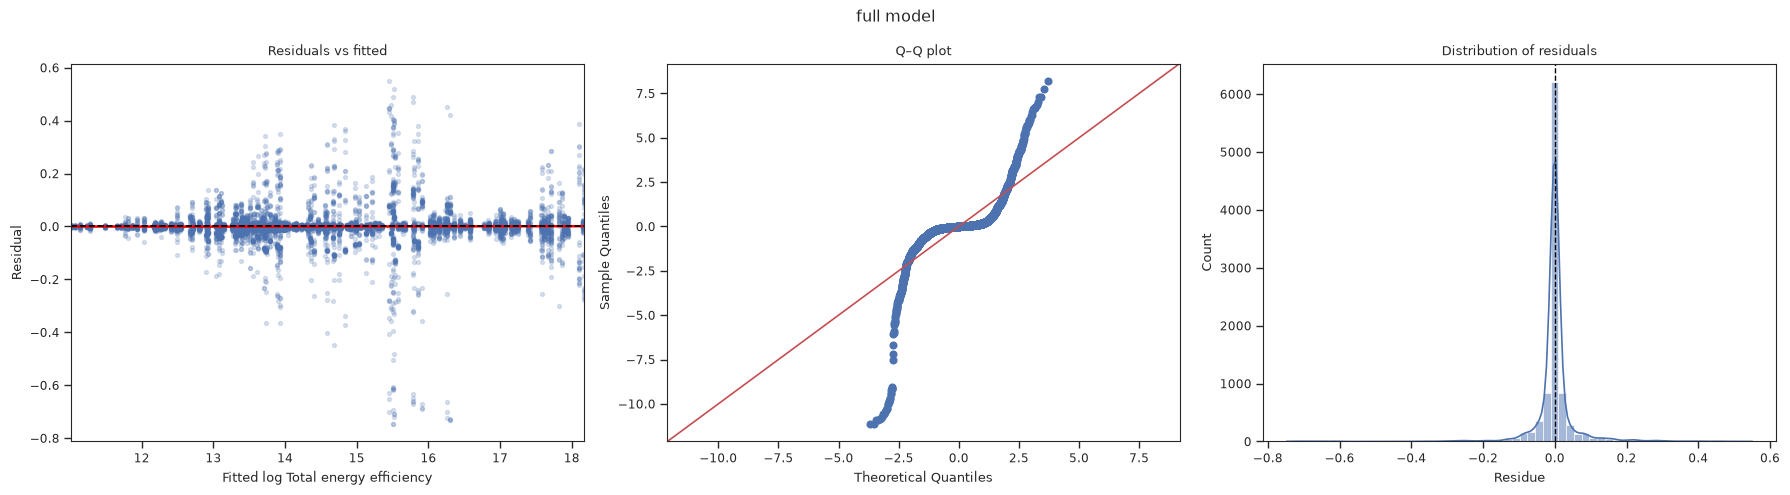

In [56]:
plot_model_diagnostics(total_full_model, "Total energy efficiency", "full model")

Net energy efficiency: full model: R²=0.998275, RMSE=0.068519


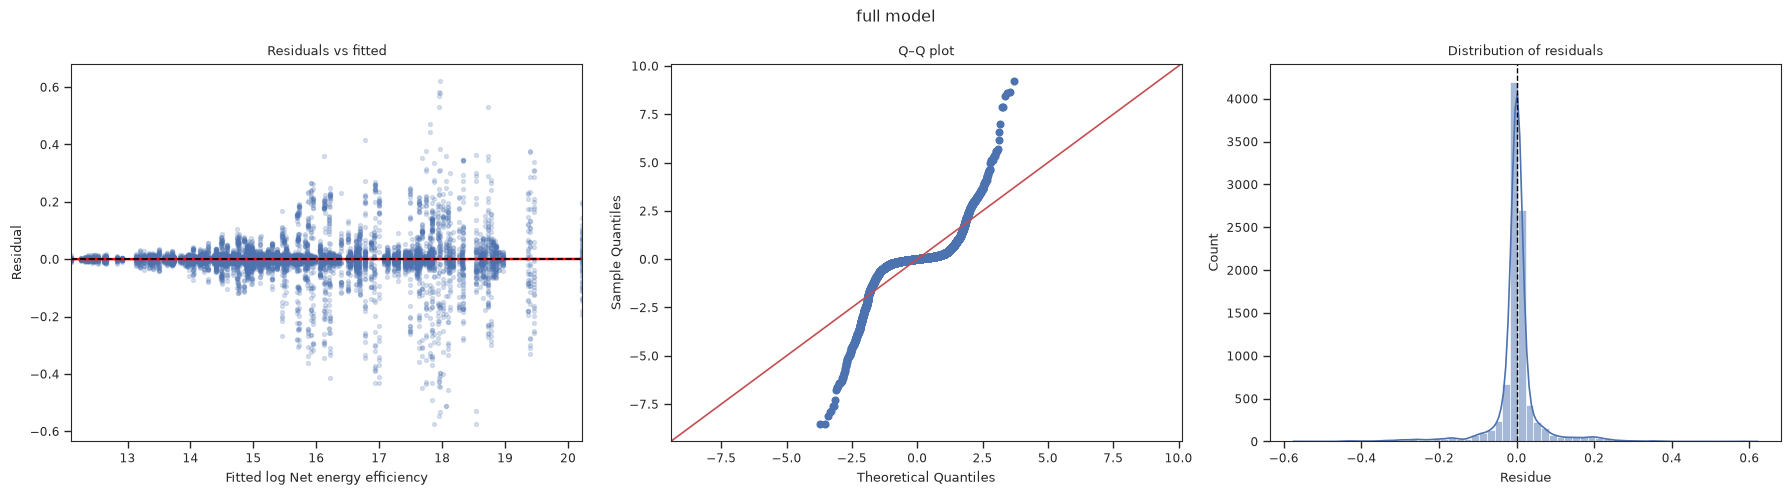

In [57]:
plot_model_diagnostics(net_full_model, "Net energy efficiency", "full model")